# Análisis de la deserción en la educación superior chilena

**Sumativa 1 — Informe técnico de avance**

Estadística Computacional · Magíster en Ciencia de Datos e Inteligencia Artificial
Universidad Andrés Bello

**Autor:** Sebastian Antunez Noguera

---

Este cuaderno aplica estadística descriptiva, estimación por intervalos y
contraste de hipótesis sobre 9.678 programas de educación superior chilena,
para caracterizar el abandono e identificar qué factores se asocian a él.

| Sección | Contenido | Indicador |
|---|---|---|
| 1 | El problema de decisión | — |
| 2 | Datos, unidad de análisis y variables | ID 1.1 |
| 3 | Estadística descriptiva | ID 1.2 |
| 4 | Estimación puntual e intervalos de confianza | ID 1.3 |
| 5 | Pruebas de hipótesis y tamaño del efecto | ID 1.4 |
| 6 | Interpretación preliminar | — |
| 7 | Limitaciones | — |

**Cómo ejecutarlo.** Con el entorno del proyecto activado y el kernel
`Python (analisis-desercion)` seleccionado, *Kernel → Restart Kernel and Run All
Cells*. Tarda menos de un minuto y no necesita ningún dato externo: el conjunto
analítico está versionado en `datos/`.

## 1. El problema de decisión

Más de la mitad de quienes ingresan a un programa de pregrado en Chile no llega
a titularse de él. El hecho tiene consecuencias para el estudiante, que pierde
tiempo y dinero; para la institución, que sostiene vacantes que no rinden; y
para el Estado, que subsidia matrículas sin contrapartida.

La situación que motiva este análisis es la siguiente: **una autoridad dispone
de presupuesto para un programa de retención que solo alcanza a cubrir una
fracción de los programas del sistema, y debe decidir dónde concentrarlo.** La
decisión se toma bajo incertidumbre, porque el abandono de cada programa no se
observa directamente, sino que se estima a partir de datos agregados.

De ahí las tres preguntas que estructuran el trabajo:

1. ¿Cuál es la magnitud del abandono y cuánto varía entre programas?
   *(estadística descriptiva)*
2. ¿Con qué precisión puede estimarse el abandono del sistema a partir de los
   datos disponibles? *(estimación e intervalos de confianza)*
3. ¿Qué características distinguen a los programas con más abandono, y cuáles
   de esas diferencias son lo bastante grandes como para orientar la decisión?
   *(contraste de hipótesis y tamaño del efecto)*

La tercera pregunta encierra el criterio que gobierna todo el análisis: una
diferencia puede ser estadísticamente significativa y, a la vez, demasiado
pequeña para justificar una política. Separar ambas cosas es el objeto del
apartado 5.

In [1]:
"""Analisis de la desercion en la educacion superior chilena.

Sumativa 1 - Informe tecnico de avance.
Estadistica Computacional, Magister en Ciencia de Datos e IA, UNAB.
"""
import importlib.metadata as meta
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from statsmodels.stats.proportion import proportion_confint

# La raiz se busca hacia arriba, de modo que el cuaderno funcione tanto si se
# ejecuta desde notebooks/ como desde la carpeta del proyecto.
RAIZ = Path.cwd()
while not (RAIZ / "datos" / "base_programas.csv").exists() and RAIZ != RAIZ.parent:
    RAIZ = RAIZ.parent
FIGURAS = RAIZ / "resultados" / "figuras"
TABLAS = RAIZ / "resultados" / "tablas"
FIGURAS.mkdir(parents=True, exist_ok=True)
TABLAS.mkdir(parents=True, exist_ok=True)

SEMILLA = 42          # toda remuestra queda reproducible
ALFA = 0.05           # nivel de significancia, declarado antes de mirar los datos
rng = np.random.default_rng(SEMILLA)

# Color con funcion: uno senala aquello de lo que se habla, el gris es contexto.
DESTACADO, NEUTRO = "#AC212E", "#9FB6C8"

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "font.size": 10, "axes.titlesize": 11,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "grid.linewidth": 0.6,
})
sns.set_style("white")


def rotular(eje, titulo, subtitulo="", fuente="Elaboracion propia a partir de bases SIES (MINEDUC)."):
    """Titulo como enunciado, subtitulo explicativo y fuente al pie."""
    eje.set_title(titulo, fontsize=11.5, fontweight="bold", loc="left", pad=26)
    if subtitulo:
        eje.text(0, 1.012, subtitulo, transform=eje.transAxes, fontsize=9,
                 color="#444444", va="bottom")
    eje.figure.text(0.01, -0.02, fuente, fontsize=7.5, color="#777777")


def guardar(fig, nombre):
    """Exporta la figura y devuelve su ruta."""
    destino = FIGURAS / f"{nombre}.png"
    fig.savefig(destino)
    return destino


print("Python", sys.version.split()[0])
for paquete in ("pandas", "numpy", "scipy", "statsmodels", "matplotlib", "seaborn"):
    print(f"  {paquete:<12} {meta.version(paquete)}")
print(f"\nRaiz del proyecto: {RAIZ}")
print(f"Semilla {SEMILLA} | nivel de significancia alfa = {ALFA}")

Python 3.14.7
  pandas       3.0.5
  numpy        2.5.3
  scipy        1.18.1
  statsmodels  0.15.0
  matplotlib   3.11.1
  seaborn      0.13.2

Raiz del proyecto: D:\Magister Ciencia de Datos\Estadística computacional\Sumativa\analisis-desercion
Semilla 42 | nivel de significancia alfa = 0.05


## 2. Datos, unidad de análisis y variables

### 2.1 Origen

El conjunto proviene de dos bases abiertas del **Servicio de Información de
Educación Superior (SIES)** del Ministerio de Educación: matrícula 2007–2026 y
titulados 2007–2025. Ambas se publican **agregadas por programa y año**, sin
registros individuales, y esa característica determina todo lo que sigue.

### 2.2 Construcción de la variable respuesta

Para cada programa se compara el número de titulados del año *y* con el ingreso
a primer año de la cohorte que debió entrar en *y − L*, donde *L* es la
duración formal de la carrera en años:

> titulación aparente = Σ titulados(*y*) ÷ Σ ingreso(*y* − *L*)
>
> **abandono = 1 − titulación aparente**

Se acumulan las titulaciones entre 2010 y 2025 y se conservan solo los
programas con al menos 100 estudiantes de ingreso acumulado, para que el
cociente no dependa de unas pocas personas.

El adjetivo **aparente** no es un adorno. Con datos agregados, quien se cambia
de carrera o de institución y se titula en otra parte cuenta aquí como
abandono, y quien se titula muy tarde puede quedar fuera de la ventana
observada. La cifra estimada es, por tanto, una cota superior del abandono
real.

### 2.3 Unidad de análisis

Cada fila es un **programa**: la combinación de carrera, institución, sede,
jornada y modalidad. No es un estudiante. Toda conclusión se referirá a
programas, y extenderla a individuos constituiría una falacia ecológica.

In [2]:
datos = pd.read_csv(RAIZ / "datos" / "base_programas.csv")

print(f"Programas:              {len(datos):>9,.0f}".replace(",", "."))
print(f"Variables:              {datos.shape[1]:>9}")
print(f"Valores faltantes:      {int(datos.isna().sum().sum()):>9}")
print(f"Ingreso minimo exigido: {datos['ingreso'].min():>9,.0f}".replace(",", "."))
print(f"Estudiantes de ingreso: {datos['ingreso'].sum():>9,.0f}".replace(",", "."))
datos.head(3)

Programas:                  9.678
Variables:                     25
Valores faltantes:              0
Ingreso minimo exigido:       100
Estudiantes de ingreso: 3.925.426


,codigo_carrera,pct_municipal,pct_pagado,pct_tp,pct_mujeres,edad_promedio,inst_acreditada,carrera_acreditada,matricula_total,ingreso,...,area_del_conocimiento,carrera_clasificacion_nivel_1,modalidad,jornada,duracion_estudio_carrera,inst_cerrada,abandono,metropolitana,log_matricula,duracion_anios
0,I100S10C10J1V1,0.532938,0.109312,0.373540,0.370556,21.344922,1.0,0.199219,88.285156,256.0,...,Tecnología,Profesional Sin Licenciatura,Presencial,Diurna,8.0,0.0,0.675781,0.0,4.480572,4.0
1,I100S10C10J2V1,0.600732,0.042855,0.538818,0.328444,25.955109,1.0,0.266423,118.368613,274.0,...,Tecnología,Profesional Sin Licenciatura,Presencial,Vespertina,8.0,0.0,0.058394,0.0,4.773804,4.0
2,I100S10C123J1V1,0.401654,0.220033,0.339067,0.381271,21.057143,1.0,0.000000,42.209524,105.0,...,Administración y Comercio,Profesional Sin Licenciatura,Presencial,Diurna,8.0,0.0,0.685714,0.0,3.742646,4.0


### 2.4 Inventario de variables y tipos *(ID 1.1)*

El tipo de cada variable determina qué estadístico la describe y qué contraste
la admite. Por eso el inventario precede al análisis y no al revés.

In [3]:
TIPOS = {
    "abandono": ("Cuantitativa continua", "Proporcion de la cohorte que no se titula (respuesta)"),
    "inst_acreditada": ("Cuantitativa continua", "Fraccion de la matricula en institucion acreditada"),
    "carrera_acreditada": ("Cuantitativa continua", "Fraccion de la matricula en carrera acreditada"),
    "pct_mujeres": ("Cuantitativa continua", "Proporcion de mujeres en la matricula"),
    "pct_municipal": ("Cuantitativa continua", "Proporcion proveniente de ensenanza municipal"),
    "pct_pagado": ("Cuantitativa continua", "Proporcion proveniente de particular pagado"),
    "pct_tp": ("Cuantitativa continua", "Proporcion proveniente de ensenanza tecnico-profesional"),
    "edad_promedio": ("Cuantitativa continua", "Edad media de la matricula, en anios"),
    "matricula_total": ("Cuantitativa continua", "Matricula media del programa"),
    "log_matricula": ("Cuantitativa continua", "Logaritmo de la matricula, para simetrizar la escala"),
    "ingreso": ("Cuantitativa discreta", "Ingreso acumulado a primer anio"),
    "titulados": ("Cuantitativa discreta", "Titulaciones acumuladas"),
    "duracion_estudio_carrera": ("Cuantitativa discreta", "Duracion formal, en semestres"),
    "duracion_anios": ("Cuantitativa discreta", "Duracion formal, en anios"),
    "clasificacion_institucion_nivel_3": ("Cualitativa nominal", "Tipo de institucion"),
    "area_del_conocimiento": ("Cualitativa nominal", "Area del conocimiento"),
    "carrera_clasificacion_nivel_1": ("Cualitativa nominal", "Tipo de carrera"),
    "region": ("Cualitativa nominal", "Region de la sede"),
    "modalidad": ("Cualitativa nominal", "Presencial, semipresencial o no presencial"),
    "jornada": ("Cualitativa nominal", "Diurna, vespertina u otra"),
    "nombre_institucion": ("Cualitativa nominal", "Institucion"),
    "codigo_carrera": ("Identificador", "Clave unica del programa"),
    "codigo_de_institucion": ("Identificador", "Clave de la institucion"),
    "metropolitana": ("Cualitativa dicotomica", "1 si la sede esta en la Region Metropolitana"),
    "inst_cerrada": ("Cualitativa dicotomica", "1 si la institucion dejo de operar"),
}

diccionario = pd.DataFrame(
    [{"variable": v, "tipo": TIPOS[v][0], "descripcion": TIPOS[v][1],
      "valores_distintos": datos[v].nunique()} for v in datos.columns]
)
diccionario.to_csv(TABLAS / "diccionario_variables.csv", index=False, encoding="utf-8-sig")
print(diccionario["tipo"].value_counts().to_string())
diccionario

tipo
Cuantitativa continua     10
Cualitativa nominal        7
Cuantitativa discreta      4
Identificador              2
Cualitativa dicotomica     2


,variable,tipo,descripcion,valores_distintos
0,codigo_carrera,Identificador,Clave unica del programa,9678
1,pct_municipal,Cuantitativa continua,Proporcion proveniente de ensenanza municipal,9678
2,pct_pagado,Cuantitativa continua,Proporcion proveniente de particular pagado,8592
3,pct_tp,Cuantitativa continua,Proporcion proveniente de ensenanza tecnico-pr...,9665
4,pct_mujeres,Cuantitativa continua,Proporcion de mujeres en la matricula,9418
5,edad_promedio,Cuantitativa continua,"Edad media de la matricula, en anios",9641
6,inst_acreditada,Cuantitativa continua,Fraccion de la matricula en institucion acredi...,1195
7,carrera_acreditada,Cuantitativa continua,Fraccion de la matricula en carrera acreditada,4720
8,matricula_total,Cuantitativa continua,Matricula media del programa,9641
9,ingreso,Cuantitativa discreta,Ingreso acumulado a primer anio,1346


Conviene detenerse en `inst_acreditada`, que parece dicotómica y no lo es: toma
1.195 valores distintos entre 0 y 1 porque es el **promedio ponderado** del
estado de acreditación a lo largo de los años de cohorte. Un programa cuya
institución perdió la acreditación a mitad del período recibe un valor
intermedio.

Tratarla como una bandera sin advertirlo sería un error de clasificación con
consecuencias directas sobre el contraste que se elija. En el apartado 5 se
comparan los dos extremos inequívocos —programas siempre acreditados frente a
nunca acreditados— y se excluyen las transiciones, cuya interpretación es
ambigua.

In [4]:
estado = pd.Series({
    "Siempre acreditada (= 1)": int((datos.inst_acreditada == 1).sum()),
    "Nunca acreditada (= 0)": int((datos.inst_acreditada == 0).sum()),
    "En transicion (0 < x < 1)": int(datos.inst_acreditada.between(0, 1, inclusive="neither").sum()),
})
print(f"Valores distintos de inst_acreditada: {datos.inst_acreditada.nunique():,}".replace(",", "."))
print()
print(estado.to_string())
print(f"\nTotal: {estado.sum():,}".replace(",", "."))

Valores distintos de inst_acreditada: 1.195

Siempre acreditada (= 1)     7672
Nunca acreditada (= 0)        757
En transicion (0 < x < 1)    1249

Total: 9.678


### 2.5 Reporte de calidad de los datos

Antes de describir nada conviene auditar el conjunto. La comprobación recorre
las cuatro familias de problemas que podrían invalidar el análisis: registros
repetidos, información ausente, valores fuera del dominio admisible e
inconsistencias aritméticas entre variables que deberían guardar una relación
conocida.

In [5]:
proporciones = datos.filter(like="pct_")

CONTROLES = [
    ("Filas completamente duplicadas", int(datos.duplicated().sum()), 0),
    ("Programas con codigo repetido", int(datos.codigo_carrera.duplicated().sum()), 0),
    ("Valores faltantes", int(datos.isna().sum().sum()), 0),
    ("Proporciones fuera de [0, 1]",
     int(((proporciones < 0) | (proporciones > 1)).sum().sum()), 0),
    ("Abandono fuera de [0, 1]",
     int(((datos.abandono < 0) | (datos.abandono > 1)).sum()), 0),
    ("Edad media fuera de 16 a 60 anios",
     int(((datos.edad_promedio < 16) | (datos.edad_promedio > 60)).sum()), 0),
    ("Programas bajo el umbral declarado de 100 de ingreso",
     int((datos.ingreso < 100).sum()), 0),
    ("Duracion fuera de 1 a 10 anios",
     int(((datos.duracion_anios < 1) | (datos.duracion_anios > 10)).sum()), None),
    ("Titulados por sobre el ingreso de la cohorte",
     int((datos.titulados > datos.ingreso).sum()), None),
]

calidad = pd.DataFrame(CONTROLES, columns=["Control", "Casos", "Esperado"])
calidad["Resultado"] = [
    "correcto" if esperado is not None and casos == esperado
    else ("correcto" if esperado is not None else "revisar")
    for _, casos, esperado in CONTROLES
]
calidad = calidad.drop(columns="Esperado")
calidad.to_csv(TABLAS / "calidad_datos.csv", index=False, encoding="utf-8-sig")
print(calidad.to_string(index=False))

                                             Control  Casos Resultado
                      Filas completamente duplicadas      0  correcto
                       Programas con codigo repetido      0  correcto
                                   Valores faltantes      0  correcto
                        Proporciones fuera de [0, 1]      0  correcto
                            Abandono fuera de [0, 1]      0  correcto
                   Edad media fuera de 16 a 60 anios      0  correcto
Programas bajo el umbral declarado de 100 de ingreso      0  correcto
                      Duracion fuera de 1 a 10 anios      1   revisar
        Titulados por sobre el ingreso de la cohorte    299   revisar


El conjunto llega limpio: **sin duplicados, sin faltantes y sin valores fuera
de dominio**. No se requiere limpieza, lo que es esperable porque ya es el
resultado de un proceso de agregación y filtrado documentado en el repositorio
de origen. Dos controles quedan marcados para revisar, y ninguno exige
corregir el dato:

- **Un programa declara doce años de duración formal**, el máximo de la escala.
  Es un caso real —una carrera de Arte y Arquitectura— y no un error de
  captura, de modo que se conserva.
- **299 programas titulan a más personas de las que ingresaron** en la ventana
  observada. No es una inconsistencia del dato sino una consecuencia del
  método: la cohorte de egreso se construye con un desfase teórico y recoge a
  quienes llegaron por convalidación o traslado. Es el origen del apilamiento
  en cero que se examina en el apartado 3.1, y la razón por la que la
  titulación aparente se acota en 1.

## 3. Estadística descriptiva *(ID 1.2)*

### 3.1 La variable respuesta

Se describe `abandono` con medidas de **tendencia central**, de **dispersión**
y de **forma**. Las tres familias son necesarias: la primera sitúa el centro de
la distribución, la segunda dice cuánto se alejan de él los programas —que es
justamente lo que interesa a quien debe focalizar— y la tercera indica si las
medidas centrales son representativas o están distorsionadas por una cola.

In [6]:
def describir(serie: pd.Series) -> pd.Series:
    """Resumen descriptivo completo: centro, dispersion y forma."""
    q1, q3 = serie.quantile([0.25, 0.75])
    return pd.Series({
        "n": len(serie),
        "Media": serie.mean(),
        "Mediana": serie.median(),
        "Moda (redondeada a 0,01)": serie.round(2).mode().iloc[0],
        "Desviacion estandar": serie.std(),
        "Varianza": serie.var(),
        "Rango": serie.max() - serie.min(),
        "Rango intercuartilico": q3 - q1,
        "Coeficiente de variacion": serie.std() / serie.mean(),
        "Minimo": serie.min(),
        "Q1": q1,
        "Q3": q3,
        "Maximo": serie.max(),
        "Asimetria": serie.skew(),
        "Curtosis (exceso)": serie.kurt(),
    })


abandono = datos["abandono"]
resumen = describir(abandono)
resumen.to_frame("valor").to_csv(TABLAS / "descriptiva_abandono.csv", encoding="utf-8-sig")
print(resumen.to_string(float_format=lambda x: f"{x:,.4f}"))

n                          9,678.0000
Media                          0.5183
Mediana                        0.5250
Moda (redondeada a 0,01)       0.0000
Desviacion estandar            0.2239
Varianza                       0.0501
Rango                          1.0000
Rango intercuartilico          0.2927
Coeficiente de variacion       0.4320
Minimo                         0.0000
Q1                             0.3764
Q3                             0.6692
Maximo                         1.0000
Asimetria                     -0.1816
Curtosis (exceso)             -0.1836


Tres lecturas del resumen anterior.

**El centro.** Media y mediana casi coinciden (0,518 y 0,525), de modo que
ninguna cola arrastra el promedio: ambas son representativas. La interpretación
es directa: en el programa típico, algo más de la mitad de la cohorte no llega
a titularse.

**La dispersión.** Una desviación estándar de 0,224 sobre una media de 0,518 da
un coeficiente de variación de 0,43. El abandono varía enormemente de un
programa a otro, y el rango intercuartílico lo confirma: la mitad central de
los programas se reparte entre 0,376 y 0,669, casi treinta puntos
porcentuales. Esa heterogeneidad es, precisamente, lo que hace que focalizar
tenga sentido: si todos los programas se parecieran, daría igual dónde
intervenir.

**La forma.** La asimetría de −0,18 y la curtosis de −0,18 describen una
distribución casi simétrica y ligeramente más plana que la normal. No hay
valores extremos que distorsionen el análisis, lo que habilita el uso de la
media y de los procedimientos paramétricos del apartado 5.

La **moda vale 0**, que en una variable centrada en 0,52 obliga a mirar los
extremos antes de seguir: el procedimiento de cálculo acota la titulación
aparente en 1, de modo que todo programa que titula al menos tantas personas
como ingresaron queda registrado con abandono exactamente cero.

In [7]:
extremos = pd.Series({
    "Abandono exactamente 0": int((abandono == 0).sum()),
    "Abandono exactamente 1": int((abandono == 1).sum()),
})
print(extremos.to_string())
print()
print(f"En conjunto, {extremos.sum() / len(abandono) * 100:.1f} % de los programas.")
print(f"Moda excluyendo el apilamiento en cero: {abandono[abandono > 0].round(2).mode().iloc[0]:.2f}")

Abandono exactamente 0    305
Abandono exactamente 1    160

En conjunto, 4.8 % de los programas.
Moda excluyendo el apilamiento en cero: 0.50


Son **305 programas (3,2 %) con abandono cero** y **160 (1,7 %) con abandono
uno**. Conviene averiguar si esos extremos describen el fenómeno o delatan un
desajuste entre las dos bases de origen, porque la interpretación cambia por
completo. El archivo `datos/diagnostico_extremos.csv` cruza cada uno de esos
465 programas con el último año en que registró matrícula y con las
titulaciones que acumuló en cualquier año.

In [8]:
diagnostico = pd.read_csv(RAIZ / "datos" / "diagnostico_extremos.csv")

resumen = diagnostico.groupby("abandono").agg(
    programas=("codigo_carrera", "size"),
    seguian_matriculando=("seguia_matriculando", "sum"),
    con_titulaciones=("titulaciones_en_cualquier_anio", lambda s: int((s > 0).sum())),
)
resumen["% seguia activo"] = (100 * resumen.seguian_matriculando / resumen.programas).round(0)
print(resumen.to_string())

sin_extremos = abandono[(abandono > 0) & (abandono < 1)]
print()
print(f"Peso en el conjunto:  {len(diagnostico) / len(datos) * 100:.2f} % de los programas")
print(f"Peso en la matricula: {diagnostico.ingreso.sum() / datos.ingreso.sum() * 100:.2f} % del ingreso")
print(f"Media con los extremos:  {abandono.mean():.4f}")
print(f"Media sin los extremos:  {sin_extremos.mean():.4f}")
print(f"Diferencia:              {abandono.mean() - sin_extremos.mean():+.4f}")

          programas  seguian_matriculando  con_titulaciones  % seguia activo
abandono                                                                    
0.0             305                   153               305             50.0
1.0             160                    14                91              9.0

Peso en el conjunto:  4.80 % de los programas
Peso en la matricula: 3.31 % del ingreso
Media con los extremos:  0.5183
Media sin los extremos:  0.5271
Diferencia:              -0.0088


El diagnóstico separa dos situaciones distintas.

**Los 160 programas con abandono uno son, en su gran mayoría, programas que
cerraron.** El 91 % dejó de matricular antes o durante el año de egreso
esperado, lo que es coherente con un programa que se discontinúa antes de
titular a su primera cohorte. Solo 14 seguían activos después de esa fecha, y
de ellos 11 sí registran titulaciones en algún año: en esos casos el cero no
describe la realidad, sino el desfase entre la ventana de observación y el
momento en que efectivamente egresaron.

**Los 305 con abandono cero responden a otra causa.** Todos registran
titulaciones y la mitad seguía matriculando, de modo que titulan al menos
tantas personas como ingresaron en la ventana: convalidaciones, traslados desde
otras carreras o cohortes que no calzan con el desfase teórico.

En conjunto, los 465 programas de ambos extremos son el 4,8 % de los casos y
el 3,3 % de la matrícula. Excluirlos desplazaría la media del sistema de 0,518
a 0,527, es decir nueve milésimas: no comprometen ninguna conclusión, pero son
el residuo visible de que la variable es *aparente* y no una medición directa.

### 3.2 Las demás variables numéricas

La respuesta no es la única variable que conviene describir: las predictoras
definen el perfil de los programas analizados y su dispersión condiciona lo
que puede detectarse después.

In [9]:
NUMERICAS = ["abandono", "inst_acreditada", "carrera_acreditada", "log_matricula",
             "pct_mujeres", "pct_municipal", "pct_pagado", "pct_tp",
             "edad_promedio", "duracion_anios", "ingreso", "titulados"]

resumen_numericas = pd.DataFrame({
    "Media": datos[NUMERICAS].mean(),
    "Mediana": datos[NUMERICAS].median(),
    "DE": datos[NUMERICAS].std(),
    "CV": datos[NUMERICAS].std() / datos[NUMERICAS].mean(),
    "Minimo": datos[NUMERICAS].min(),
    "Maximo": datos[NUMERICAS].max(),
    "Asimetria": datos[NUMERICAS].skew(),
})
resumen_numericas.to_csv(TABLAS / "descriptiva_numericas.csv", encoding="utf-8-sig")
print(resumen_numericas.to_string(float_format=lambda x: f"{x:,.3f}"))

                     Media  Mediana      DE    CV  Minimo    Maximo  Asimetria
abandono             0.518    0.525   0.224 0.432   0.000     1.000     -0.182
inst_acreditada      0.873    1.000   0.301 0.345   0.000     1.000     -2.248
carrera_acreditada   0.320    0.241   0.340 1.061   0.000     1.000      0.542
log_matricula        4.734    4.652   0.687 0.145   2.776     8.303      0.608
pct_mujeres          0.516    0.532   0.296 0.574   0.000     1.000     -0.133
pct_municipal        0.396    0.368   0.174 0.440   0.003     0.955      0.482
pct_pagado           0.067    0.026   0.122 1.835   0.000     0.975      3.904
pct_tp               0.387    0.396   0.193 0.498   0.000     0.990     -0.026
edad_promedio       24.160   22.688   3.487 0.144  18.700    40.878      1.206
duracion_anios       3.418    2.500   1.200 0.351   1.000    12.000      0.458
ingreso            405.603  271.000 425.667 1.049 100.000 9,994.000      5.688
titulados          213.069  128.000 276.767 1.299   

Dos rasgos del perfil importan para lo que sigue. El **87 % de la matrícula
cursa en instituciones acreditadas** pero solo el **32 % en carreras
acreditadas**: la acreditación de carrera es mucho más escasa y discrimina
mejor. Y las variables de tamaño —`ingreso` y `titulados`— son fuertemente
asimétricas, con coeficientes de variación por encima de 1; por eso el análisis
usa `log_matricula` y no la matrícula bruta cuando necesita una escala
comparable.

### 3.3 Las variables cualitativas: frecuencias

Para las variables cualitativas la descripción pertinente no son medias sino
**frecuencias absolutas y relativas**, que dicen cómo se reparte el conjunto y
advierten qué categorías tienen pocos casos, algo decisivo al elegir después un
contraste.

In [10]:
CUALITATIVAS = ["clasificacion_institucion_nivel_3", "carrera_clasificacion_nivel_1",
                "jornada", "modalidad"]


def frecuencias(variable: str) -> pd.DataFrame:
    """Frecuencia absoluta, relativa y acumulada de una variable cualitativa."""
    absoluta = datos[variable].value_counts()
    tabla = pd.DataFrame({
        "Frecuencia": absoluta,
        "Relativa (%)": (100 * absoluta / len(datos)).round(1),
    })
    tabla["Acumulada (%)"] = tabla["Relativa (%)"].cumsum().round(1)
    return tabla


for variable in CUALITATIVAS:
    tabla = frecuencias(variable)
    tabla.to_csv(TABLAS / f"frecuencias_{variable}.csv", encoding="utf-8-sig")
    print(f"--- {variable}  (n = {len(datos):,})".replace(",", "."))
    print(tabla.to_string())
    print()

--- clasificacion_institucion_nivel_3  (n = 9.678)
                                        Frecuencia  Relativa (%)  Acumulada (%)
clasificacion_institucion_nivel_3                                              
Institutos Profesionales                      3759          38.8           38.8
Centros de Formación Técnica Privados         2263          23.4           62.2
Universidades Privadas                        2012          20.8           83.0
Universidades Estatales CRUCH                  932           9.6           92.6
Universidades Privadas CRUCH                   685           7.1           99.7
Centros de Formación Técnica Estatales          27           0.3          100.0

--- carrera_clasificacion_nivel_1  (n = 9.678)
                               Frecuencia  Relativa (%)  Acumulada (%)
carrera_clasificacion_nivel_1                                         
Técnico de Nivel Superior            5009          51.8           51.8
Profesional Con Licenciatura         2890       

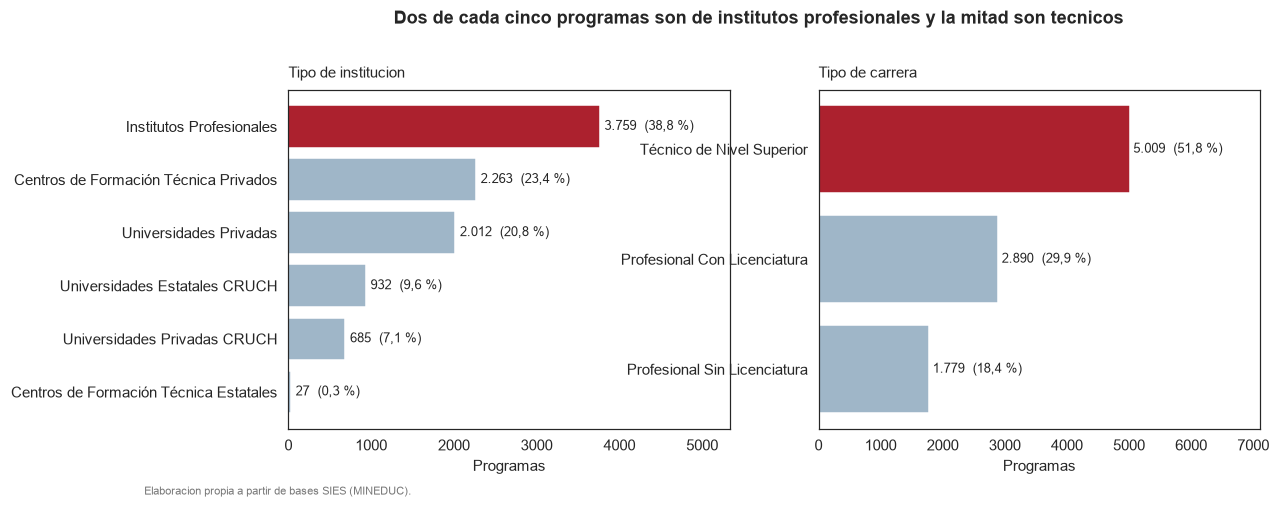

In [11]:
# --- Figura: como se reparte el conjunto -----------------------------------
fig, ejes = plt.subplots(1, 2, figsize=(11.4, 4.0))

for eje, variable, titulo in zip(
        ejes, ["clasificacion_institucion_nivel_3", "carrera_clasificacion_nivel_1"],
        ["Tipo de institucion", "Tipo de carrera"]):
    tabla = frecuencias(variable).sort_values("Frecuencia")
    # Se destaca la categoria mayoritaria, que concentra el peso del conjunto.
    colores = [DESTACADO if v == tabla["Frecuencia"].max() else NEUTRO
               for v in tabla["Frecuencia"]]
    eje.barh(tabla.index, tabla["Frecuencia"], color=colores, edgecolor="white")
    for y, (n, pct) in enumerate(zip(tabla["Frecuencia"], tabla["Relativa (%)"])):
        etiqueta = f"{n:,}".replace(",", ".") + "  (" + f"{pct:.1f}".replace(".", ",") + " %)"
        eje.text(n + 60, y, etiqueta, va="center", fontsize=8.5)
    eje.set_xlim(0, tabla["Frecuencia"].max() * 1.42)
    eje.set_xlabel("Programas")
    eje.set_title(titulo, fontsize=10, loc="left", pad=8)

ejes[0].figure.suptitle(
    "Dos de cada cinco programas son de institutos profesionales y la mitad son tecnicos",
    fontsize=11.5, fontweight="bold", x=0.5, y=1.06)
ejes[0].figure.text(0.01, -0.04, "Elaboracion propia a partir de bases SIES (MINEDUC).",
                    fontsize=7.5, color="#777777")
guardar(fig, "fig5_frecuencias")
plt.show()

El reparto no es uniforme y eso condiciona el análisis. Los **institutos
profesionales concentran el 38,8 %** de los programas y las carreras **técnicas
de nivel superior el 51,8 %**, mientras que los centros de formación técnica
estatales son apenas 27 programas (0,3 %). En el otro extremo, la modalidad
presencial cubre el 96,4 % del conjunto, de modo que las comparaciones por
modalidad descansan sobre menos de 350 casos y conviene leerlas con cautela.

Esa asimetría es la razón por la que el contraste del apartado 5 sobre tipo de
institución se plantea como prueba de independencia y no como comparación de
medias: con una categoría de 27 casos, un contraste de medias tendría una
potencia muy desigual entre grupos.

### 3.4 El abandono por grupos

La media global oculta las diferencias que importan para decidir. Se describe
entonces el abandono dentro de cada categoría de las tres variables
cualitativas con mayor interés para la política: tipo de institución, jornada y
área del conocimiento.

In [12]:
def por_grupo(variable: str, minimo: int = 0) -> pd.DataFrame:
    """Descriptivos del abandono dentro de cada categoria."""
    g = datos.groupby(variable)["abandono"]
    tabla = pd.DataFrame({
        "n": g.size(),
        "Media": g.mean(),
        "Mediana": g.median(),
        "DE": g.std(),
        "Q1": g.quantile(0.25),
        "Q3": g.quantile(0.75),
    })
    return tabla[tabla["n"] >= minimo].sort_values("Media", ascending=False)


for variable in ("clasificacion_institucion_nivel_3", "jornada", "area_del_conocimiento"):
    tabla = por_grupo(variable)
    tabla.to_csv(TABLAS / f"descriptiva_por_{variable}.csv", encoding="utf-8-sig")
    print(f"--- {variable} ---")
    print(tabla.to_string(float_format=lambda x: f"{x:,.3f}"))
    print()

--- clasificacion_institucion_nivel_3 ---
                                           n  Media  Mediana    DE    Q1    Q3
clasificacion_institucion_nivel_3                                             
Centros de Formación Técnica Estatales    27  0.565    0.564 0.127 0.477 0.657
Centros de Formación Técnica Privados   2263  0.542    0.541 0.195 0.415 0.677
Institutos Profesionales                3759  0.528    0.542 0.232 0.389 0.681
Universidades Privadas                  2012  0.509    0.512 0.237 0.355 0.672
Universidades Estatales CRUCH            932  0.494    0.481 0.223 0.341 0.646
Universidades Privadas CRUCH             685  0.442    0.442 0.213 0.284 0.594

--- jornada ---
               n  Media  Mediana    DE    Q1    Q3
jornada                                           
Vespertina  3439  0.547    0.571 0.233 0.424 0.703
Otra         309  0.536    0.577 0.305 0.304 0.754
Diurna      5930  0.501    0.500 0.212 0.359 0.643

--- area_del_conocimiento ---
                       

La distancia entre el tipo de institución con más abandono y el que menos tiene
es de **12,3 puntos porcentuales**; entre áreas del conocimiento llega a
**17,5 puntos**. Son diferencias de una magnitud que sí permitiría priorizar,
y el apartado 5 las somete a contraste formal.

### 3.5 Análisis bivariado

Hasta aquí cada variable se ha descrito por separado. El paso siguiente examina
cómo se relacionan entre sí, que es lo que permite anticipar qué factores
merecen un contraste formal y cuáles podrían estar midiendo lo mismo.

In [13]:
NUM_CORR = ["abandono", "inst_acreditada", "carrera_acreditada", "log_matricula",
            "pct_mujeres", "pct_municipal", "pct_pagado", "pct_tp",
            "edad_promedio", "duracion_anios"]

matriz = datos[NUM_CORR].corr()
matriz.to_csv(TABLAS / "matriz_correlaciones.csv", encoding="utf-8-sig")

con_abandono = matriz["abandono"].drop("abandono").sort_values()
print("Correlacion de Pearson con el abandono")
print(con_abandono.to_string(float_format=lambda x: f"{x:+.3f}"))

print()
print("Contraste de significacion de cada correlacion")
for variable in con_abandono.index:
    r, p = stats.pearsonr(datos[variable], datos["abandono"])
    print(f"  {variable:<20} r = {r:+.3f}   p = {p:.2e}   r2 = {r**2:.3f}")

Correlacion de Pearson con el abandono
carrera_acreditada   -0.311
inst_acreditada      -0.259
log_matricula        -0.247
pct_mujeres          -0.165
duracion_anios       -0.146
pct_pagado           -0.103
pct_municipal        +0.050
pct_tp               +0.086
edad_promedio        +0.092

Contraste de significacion de cada correlacion
  carrera_acreditada   r = -0.311   p = 6.49e-216   r2 = 0.097
  inst_acreditada      r = -0.259   p = 3.12e-148   r2 = 0.067
  log_matricula        r = -0.247   p = 1.05e-134   r2 = 0.061
  pct_mujeres          r = -0.165   p = 6.62e-60   r2 = 0.027
  duracion_anios       r = -0.146   p = 3.22e-47   r2 = 0.021
  pct_pagado           r = -0.103   p = 1.94e-24   r2 = 0.011
  pct_municipal        r = +0.050   p = 7.82e-07   r2 = 0.003
  pct_tp               r = +0.086   p = 3.57e-17   r2 = 0.007
  edad_promedio        r = +0.092   p = 7.75e-20   r2 = 0.009


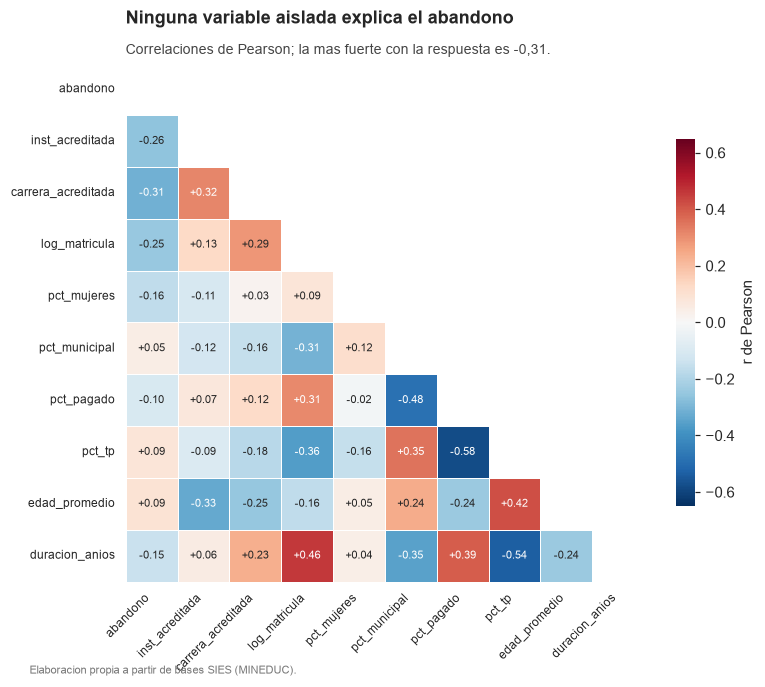

In [14]:
# --- Figura: la matriz completa -------------------------------------------
fig, eje = plt.subplots(figsize=(7.6, 6.2))
mascara = np.triu(np.ones_like(matriz, dtype=bool))
sns.heatmap(matriz, mask=mascara, annot=True, fmt="+.2f", annot_kws={"size": 7.5},
            cmap="RdBu_r", center=0, vmin=-0.65, vmax=0.65, square=True,
            linewidths=0.6, linecolor="white", cbar_kws={"shrink": 0.7, "label": "r de Pearson"},
            ax=eje)
eje.set_xticklabels(eje.get_xticklabels(), rotation=45, ha="right", fontsize=8)
eje.set_yticklabels(eje.get_yticklabels(), rotation=0, fontsize=8)
eje.grid(False)
rotular(eje,
        "Ninguna variable aislada explica el abandono",
        "Correlaciones de Pearson; la mas fuerte con la respuesta es -0,31.")
guardar(fig, "fig6_correlaciones")
plt.show()

La lectura bivariada deja tres conclusiones.

**Ninguna variable aislada explica el abandono.** La correlación más fuerte es
la de la acreditación de carrera, con r = −0,311, que equivale a un 9,7 % de
varianza compartida. Las demás no superan 0,26 en valor absoluto. El fenómeno
es multifactorial, lo que anticipa que ningún criterio único de focalización
será suficiente.

**El signo de cada relación es coherente con lo esperado.** Acreditación,
tamaño del programa, proporción de mujeres y duración formal se asocian
negativamente con el abandono; la edad media de la matrícula y el origen
técnico-profesional, positivamente. Ninguna correlación contradice lo que la
literatura sobre retención haría prever, lo que da verosimilitud al conjunto.

**Hay colinealidad entre las predictoras.** El par más correlacionado es
`pct_pagado` con `pct_tp` (r = −0,583), seguido de `pct_tp` con `duracion_anios`
(r = −0,535): los programas que reciben egresados de enseñanza
técnico-profesional son los más cortos y los que menos estudiantes de colegios
particulares pagados reciben. Esa estructura es importante para la fase
siguiente, porque un modelo multivariado no podrá separar limpiamente esos
efectos.

Conviene advertir que **todas las correlaciones son significativas al 5 %**,
incluso la de 0,050. Es el mismo fenómeno que domina el apartado 5: con 9.678
observaciones, la significación estadística deja de informar sobre la
relevancia.

### 3.6 Las figuras del análisis

Cuatro figuras, una por cada pregunta que la descripción deja abierta. En todas
el color cumple una función: señala aquello de lo que habla el texto, mientras
el gris es contexto. El título enuncia el hallazgo en lugar de nombrar las
variables.

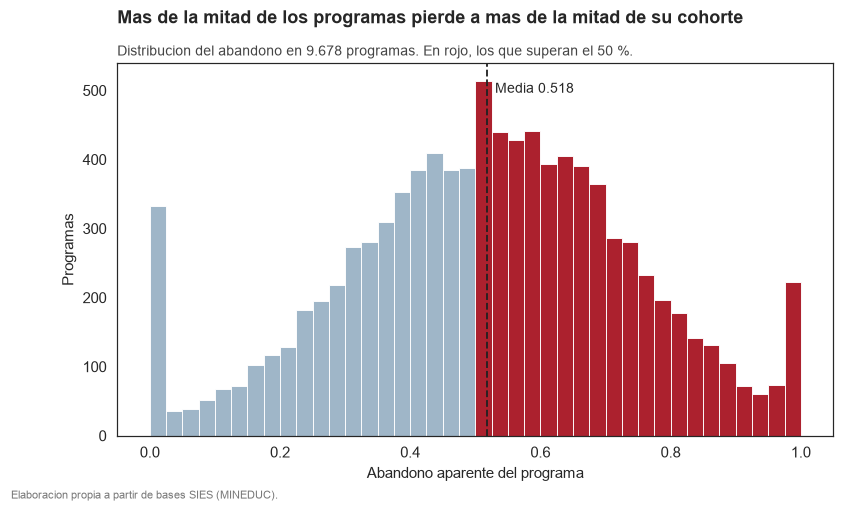

In [15]:
# --- Figura 1: la distribucion completa -----------------------------------
fig, eje = plt.subplots(figsize=(8.4, 4.4))
n, bordes, barras = eje.hist(abandono, bins=40, color=NEUTRO,
                             edgecolor="white", linewidth=0.6)
# El color destaca el tramo que concentra la decision: abandono sobre 50 %.
for borde, barra in zip(bordes[:-1], barras):
    if borde >= 0.5:
        barra.set_facecolor(DESTACADO)

eje.axvline(abandono.mean(), color="#222222", linestyle="--", linewidth=1.2)
eje.text(abandono.mean() + 0.012, eje.get_ylim()[1] * 0.92,
         f"Media {abandono.mean():.3f}", fontsize=9)
eje.set_xlabel("Abandono aparente del programa")
eje.set_ylabel("Programas")
total = f"{len(datos):,}".replace(",", ".")   # solo el numero, no la frase
rotular(eje,
        "Mas de la mitad de los programas pierde a mas de la mitad de su cohorte",
        f"Distribucion del abandono en {total} programas. En rojo, los que superan el 50 %.")
guardar(fig, "fig1_distribucion")
plt.show()

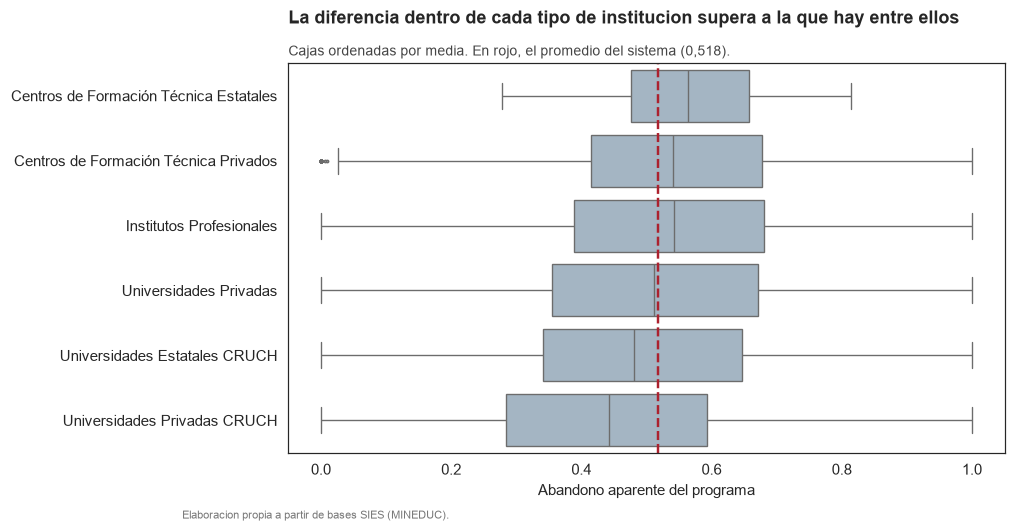

In [16]:
# --- Figura 2: dispersion dentro de cada tipo de institucion ---------------
orden = por_grupo("clasificacion_institucion_nivel_3").index.tolist()
fig, eje = plt.subplots(figsize=(8.4, 4.6))
sns.boxplot(data=datos, y="clasificacion_institucion_nivel_3", x="abandono",
            order=orden, color=NEUTRO, fliersize=1.5, linewidth=0.9, ax=eje)
eje.axvline(abandono.mean(), color=DESTACADO, linestyle="--", linewidth=1.6)
eje.set_xlabel("Abandono aparente del programa")
eje.set_ylabel("")
rotular(eje,
        "La diferencia dentro de cada tipo de institucion supera a la que hay entre ellos",
        "Cajas ordenadas por media. En rojo, el promedio del sistema (0,518).")
guardar(fig, "fig2_tipo_institucion")
plt.show()

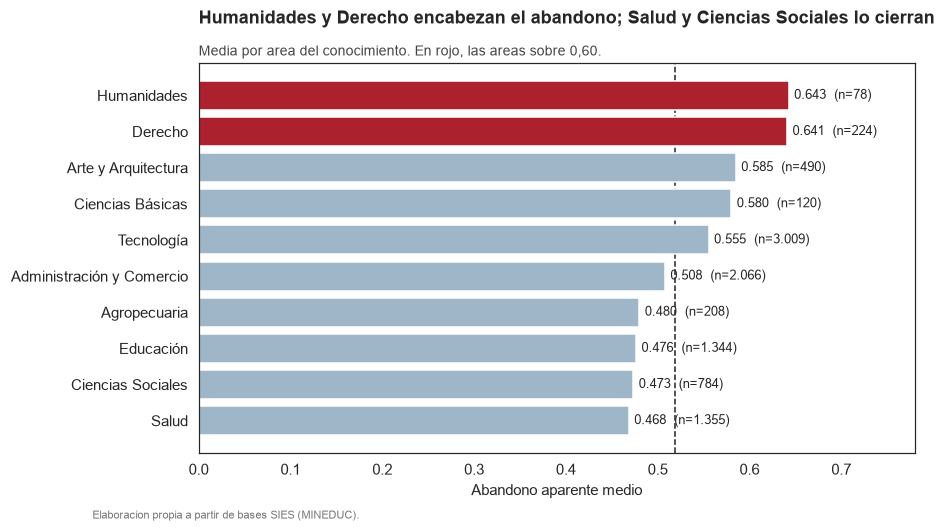

In [17]:
# --- Figura 3: el area del conocimiento ------------------------------------
area = por_grupo("area_del_conocimiento").sort_values("Media")
fig, eje = plt.subplots(figsize=(8.4, 4.6))
colores = [DESTACADO if v >= 0.60 else NEUTRO for v in area["Media"]]
eje.barh(area.index, area["Media"], color=colores, edgecolor="white")
eje.axvline(abandono.mean(), color="#222222", linestyle="--", linewidth=1.0, zorder=0)
for y, (valor, n) in enumerate(zip(area["Media"], area["n"])):
    eje.text(valor + 0.006, y, f"{valor:.3f}  (n={n:,})".replace(",", "."),
             va="center", fontsize=8.5)
eje.set_xlim(0, 0.78)
eje.set_xlabel("Abandono aparente medio")
rotular(eje,
        "Humanidades y Derecho encabezan el abandono; Salud y Ciencias Sociales lo cierran",
        "Media por area del conocimiento. En rojo, las areas sobre 0,60.")
guardar(fig, "fig3_areas")
plt.show()

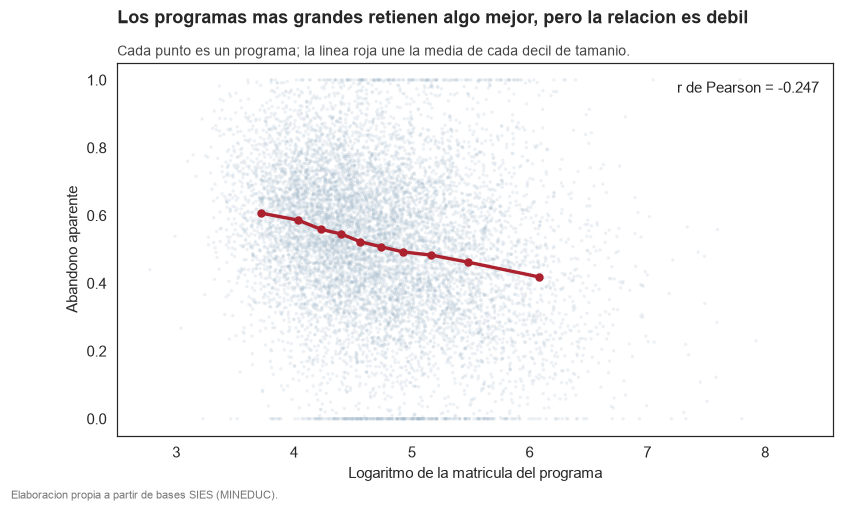

Correlacion de Pearson: r = -0.2472 (p = 1.05e-134); r^2 = 0.0611


In [18]:
# --- Figura 4: relacion con el tamanio del programa ------------------------
fig, eje = plt.subplots(figsize=(8.4, 4.4))
eje.scatter(datos["log_matricula"], datos["abandono"], s=5, alpha=0.18,
            color=NEUTRO, edgecolors="none")

# Media del abandono por decil de tamanio: la tendencia que el punto a punto esconde.
deciles = pd.qcut(datos["log_matricula"], 10)
tendencia = datos.groupby(deciles, observed=True).agg(
    x=("log_matricula", "mean"), y=("abandono", "mean"))
eje.plot(tendencia["x"], tendencia["y"], color=DESTACADO, linewidth=2.2,
         marker="o", markersize=4.5)

r, p_r = stats.pearsonr(datos["log_matricula"], datos["abandono"])
eje.text(0.98, 0.95, f"r de Pearson = {r:+.3f}", transform=eje.transAxes,
         ha="right", va="top", fontsize=9.5)
eje.set_xlabel("Logaritmo de la matricula del programa")
eje.set_ylabel("Abandono aparente")
rotular(eje,
        "Los programas mas grandes retienen algo mejor, pero la relacion es debil",
        "Cada punto es un programa; la linea roja une la media de cada decil de tamanio.")
guardar(fig, "fig4_tamanio")
plt.show()
print(f"Correlacion de Pearson: r = {r:+.4f} (p = {p_r:.2e}); r^2 = {r**2:.4f}")

Las cuatro figuras permiten leer lo que la tabla sola no muestra.

La **figura 1** sitúa la magnitud: la distribución es ancha y está centrada
justo en el umbral del 50 %, de modo que el 54,9 % de los programas lo supera.

La **figura 2** contiene la advertencia más importante para la decisión. Las
cajas se solapan ampliamente: la variación *dentro* de cada tipo de institución
es mayor que la que hay *entre* tipos. Focalizar por tipo de institución, que
sería lo administrativamente más cómodo, dejaría fuera a buena parte de los
programas con más abandono.

La **figura 3** muestra un gradiente por área del conocimiento más marcado,
aunque con tamaños de grupo muy desiguales —de 78 programas en Humanidades a
3.009 en Tecnología—, lo que obliga a acompañar cada media de su intervalo.

La **figura 4** descarta una explicación simple: el tamaño del programa se
asocia negativamente con el abandono, pero la correlación es débil y explica
una fracción mínima de la variación.

## 4. Estimación puntual e intervalos de confianza *(ID 1.3)*

### 4.1 Qué población se está estimando

Antes de calcular un intervalo conviene responder una pregunta que suele
saltarse: **¿de qué población se habla?** Los 9.678 programas no son una
muestra extraída al azar de un universo mayor: son todos los programas de
pregrado chilenos que cumplen los criterios de inclusión en el período
2010–2025. Sobre un censo, un intervalo de confianza en sentido estricto
carecería de sentido, porque el parámetro ya está medido sin error muestral.

La inferencia que sigue se formula, por tanto, sobre el **proceso generador**:
los programas observados se tratan como una realización de un sistema
educativo que sigue operando y que podría haber producido resultados algo
distintos. El parámetro estimado es el abandono esperado de ese proceso, y el
intervalo mide cuánta incertidumbre introduce la variabilidad del sistema, no
el muestreo.

Esta declaración no es un formalismo: cambia lo que puede afirmarse. Permite
decir «el abandono esperado del sistema está entre 0,514 y 0,523», y prohíbe
decir «hay un 95 % de probabilidad de que el abandono real caiga ahí», que es
la lectura bayesiana que el intervalo frecuentista no autoriza.

In [19]:
def ic_media(serie: pd.Series, confianza: float = 0.95) -> dict:
    """Estimacion puntual e intervalo para la media, por el metodo t."""
    n = len(serie)
    media, ee = serie.mean(), stats.sem(serie)
    inferior, superior = stats.t.interval(confianza, n - 1, loc=media, scale=ee)
    return {"n": n, "estimacion": media, "error_estandar": ee,
            "gl": n - 1, "inferior": inferior, "superior": superior,
            "amplitud": superior - inferior}


media = ic_media(abandono)
print("Parametro: abandono esperado del sistema")
print(f"  Estimacion puntual (media muestral): {media['estimacion']:.4f}")
print(f"  Error estandar: {media['error_estandar']:.5f}  =  {abandono.std():.4f} / raiz({len(abandono):,})".replace(",", "."))
print(f"  Grados de libertad: {media['gl']:,}".replace(",", "."))
print(f"  IC 95 % (t de Student): [{media['inferior']:.4f}, {media['superior']:.4f}]")
print(f"  Amplitud: {media['amplitud']:.4f}  ({media['amplitud']*100:.2f} puntos porcentuales)")

Parametro: abandono esperado del sistema
  Estimacion puntual (media muestral): 0.5183
  Error estandar: 0.00228  =  0.2239 / raiz(9.678)
  Grados de libertad: 9.677
  IC 95 % (t de Student): [0.5138, 0.5227]
  Amplitud: 0.0089  (0.89 puntos porcentuales)


El intervalo mide nueve milésimas de ancho. Esa precisión no proviene de que el
fenómeno sea homogéneo —la desviación estándar de 0,224 dice lo contrario—
sino del tamaño del conjunto: el error estándar divide la desviación por la
raíz de 9.678, es decir por 98,4.

**Conviene no confundir precisión con homogeneidad.** El intervalo describe
cuán bien conocemos el *promedio*; no dice nada sobre cuán parecidos son los
programas entre sí. Para la decisión de focalización, la segunda magnitud
importa más que la primera.

In [20]:
# Verificacion por remuestreo: el IC t supone normalidad de la media muestral,
# que el teorema central del limite garantiza a este tamanio. El bootstrap no
# necesita ese supuesto, de modo que su coincidencia lo confirma.
remuestras = np.array([
    rng.choice(abandono.values, size=len(abandono), replace=True).mean()
    for _ in range(5000)
])
bo_inf, bo_sup = np.percentile(remuestras, [2.5, 97.5])

print(f"IC 95 % parametrico (t):   [{media['inferior']:.4f}, {media['superior']:.4f}]")
print(f"IC 95 % bootstrap (5.000): [{bo_inf:.4f}, {bo_sup:.4f}]")
print(f"\nDiferencia entre ambos limites: {abs(bo_inf-media['inferior']):.5f} y {abs(bo_sup-media['superior']):.5f}")
print("Coinciden hasta la cuarta cifra: el supuesto de normalidad de la media es sostenible.")

IC 95 % parametrico (t):   [0.5138, 0.5227]
IC 95 % bootstrap (5.000): [0.5139, 0.5226]

Diferencia entre ambos limites: 0.00006 y 0.00016
Coinciden hasta la cuarta cifra: el supuesto de normalidad de la media es sostenible.


### 4.2 Estimación de tres variables numéricas

Se estiman primero las medias poblacionales de tres variables numéricas que
describen dimensiones distintas del programa: **el abandono**, que es la
respuesta; **la edad media de la matrícula**, que aproxima el perfil del
estudiante; y **la proporción de mujeres**, que describe su composición. Las
tres se estiman por el mismo procedimiento, el intervalo t para la media,
porque las tres son continuas y el tamaño del conjunto garantiza la normalidad
de la media muestral.

In [21]:
TRES = ["abandono", "edad_promedio", "pct_mujeres"]

estimadas = pd.DataFrame([
    {"Variable": v, **{k: val for k, val in ic_media(datos[v]).items()}}
    for v in TRES
]).set_index("Variable")
estimadas["DE"] = [datos[v].std() for v in TRES]
estimadas = estimadas[["n", "estimacion", "DE", "error_estandar", "inferior", "superior", "amplitud"]]
estimadas.columns = ["n", "Estimacion", "DE", "Error estandar", "IC inferior", "IC superior", "Amplitud"]
estimadas.to_csv(TABLAS / "estimaciones_tres_variables.csv", encoding="utf-8-sig")
print(estimadas.to_string(float_format=lambda x: f"{x:,.4f}"))

                  n  Estimacion     DE  Error estandar  IC inferior  IC superior  Amplitud
Variable                                                                                  
abandono       9678      0.5183 0.2239          0.0023       0.5138       0.5227    0.0089
edad_promedio  9678     24.1600 3.4874          0.0354      24.0905      24.2295    0.1390
pct_mujeres    9678      0.5156 0.2958          0.0030       0.5097       0.5215    0.0118


Los tres intervalos son muy estrechos y conviene leerlos con cuidado, porque la
precisión de la estimación no se traslada a la homogeneidad del fenómeno.

- **Abandono:** 0,5183, con intervalo [0,5138 ; 0,5227]. En el programa medio
  algo más de la mitad de la cohorte no se titula.
- **Edad media de la matrícula:** 24,16 años, con intervalo
  [24,09 ; 24,23]. Es una edad alta para pregrado y refleja el peso de la
  jornada vespertina, que agrupa al 35,5 % de los programas.
- **Proporción de mujeres:** 0,5156, con intervalo [0,5097 ; 0,5215]. El
  sistema está equilibrado en promedio, pero la desviación estándar de 0,296
  revela una segregación fuerte por programa: hay carreras casi enteramente
  masculinas y otras casi enteramente femeninas.

El tercer caso ilustra bien el punto: una media del 51,6 % con un intervalo de
seis milésimas de ancho sería engañosa si se leyera como que los programas
están equilibrados. Lo que el intervalo afirma es que *el promedio del sistema*
se conoce con mucha precisión, no que los programas se parezcan entre sí.

### 4.3 Estimación de una proporción

A las tres medias se añaden dos parámetros de naturaleza distinta, que exigen
procedimientos propios. El primero es la **proporción de programas cuyo
abandono supera el 50 %**, la magnitud con que una autoridad dimensionaría el
problema. Al tratarse de una proporción el intervalo adecuado no es el de la
media sino el de Wilson, que a diferencia de la aproximación normal no produce
límites fuera de [0, 1] y mantiene su cobertura cuando la proporción se acerca
a los extremos.

In [22]:
exitos = int((abandono > 0.5).sum())
n = len(abandono)
p_gorro = exitos / n

wilson = proportion_confint(exitos, n, alpha=1 - 0.95, method="wilson")
normal = proportion_confint(exitos, n, alpha=1 - 0.95, method="normal")

print("Parametro: proporcion de programas con abandono superior al 50 %")
print(f"  Estimacion puntual: {p_gorro:.4f}  ({exitos:,} de {n:,})".replace(",", "."))
print(f"  IC 95 % de Wilson:  [{wilson[0]:.4f}, {wilson[1]:.4f}]")
print(f"  IC 95 % normal:     [{normal[0]:.4f}, {normal[1]:.4f}]")
print("\nAmbos coinciden porque p esta cerca de 0,5 y n es grande;")
print("con proporciones extremas el de Wilson seria claramente preferible.")

Parametro: proporcion de programas con abandono superior al 50 %
  Estimacion puntual: 0.5494  (5.317 de 9.678)
  IC 95 % de Wilson:  [0.5395, 0.5593]
  IC 95 % normal:     [0.5395, 0.5593]

Ambos coinciden porque p esta cerca de 0,5 y n es grande;
con proporciones extremas el de Wilson seria claramente preferible.


### 4.4 Estimación de una diferencia

El quinto parámetro es el que más interesa para decidir: **cuánto mayor es el
abandono en los programas de instituciones no acreditadas**. Se comparan los
dos extremos inequívocos de `inst_acreditada` —siempre acreditada frente a
nunca acreditada— y se excluyen los 1.249 programas en transición, cuya
posición es ambigua.

El intervalo de una diferencia de medias responde a la pregunta que la
estimación puntual deja abierta: no solo cuánto difieren, sino qué rango de
diferencias es compatible con los datos.

In [23]:
siempre = datos.loc[datos.inst_acreditada == 1, "abandono"]
nunca = datos.loc[datos.inst_acreditada == 0, "abandono"]


def ic_diferencia(a: pd.Series, b: pd.Series, confianza: float = 0.95) -> dict:
    """IC de Welch para la diferencia de medias, sin suponer varianzas iguales."""
    n1, n2 = len(a), len(b)
    v1, v2 = a.var(ddof=1), b.var(ddof=1)
    diferencia = a.mean() - b.mean()
    ee = np.sqrt(v1 / n1 + v2 / n2)
    gl = (v1 / n1 + v2 / n2) ** 2 / ((v1 / n1) ** 2 / (n1 - 1) + (v2 / n2) ** 2 / (n2 - 1))
    inferior, superior = stats.t.interval(confianza, gl, loc=diferencia, scale=ee)
    return {"diferencia": diferencia, "error_estandar": ee, "gl": gl,
            "inferior": inferior, "superior": superior}


dif = ic_diferencia(nunca, siempre)
print(f"Nunca acreditada:   n = {len(nunca):>5,}   media = {nunca.mean():.4f}   DE = {nunca.std():.4f}".replace(",", "."))
print(f"Siempre acreditada: n = {len(siempre):>5,}   media = {siempre.mean():.4f}   DE = {siempre.std():.4f}".replace(",", "."))
print()
print("Parametro: diferencia de abandono esperado entre ambos grupos")
print(f"  Estimacion puntual: {dif['diferencia']:+.4f}  ({dif['diferencia']*100:.1f} puntos porcentuales)")
print(f"  IC 95 % (Welch):    [{dif['inferior']:.4f}, {dif['superior']:.4f}]")
print(f"  Grados de libertad: {dif['gl']:.0f}")
print("\nEl intervalo no contiene el cero: la diferencia es compatible con los datos")
print("en todo su rango, y su limite inferior ya es de 15,9 puntos porcentuales.")

Nunca acreditada:   n =   757   media = 0.6636   DE = 0.2243
Siempre acreditada: n = 7.672   media = 0.4879   DE = 0.2178

Parametro: diferencia de abandono esperado entre ambos grupos
  Estimacion puntual: +0.1757  (17.6 puntos porcentuales)
  IC 95 % (Welch):    [0.1590, 0.1924]
  Grados de libertad: 902

El intervalo no contiene el cero: la diferencia es compatible con los datos
en todo su rango, y su limite inferior ya es de 15,9 puntos porcentuales.


In [24]:
# Resumen de los tres parametros estimados
estimaciones = pd.DataFrame([
    {"Parametro": "Abandono esperado del sistema", "Tipo": "Media",
     "Estimacion": media["estimacion"], "IC inferior": media["inferior"],
     "IC superior": media["superior"], "Metodo": "t de Student"},
    {"Parametro": "Programas con abandono > 50 %", "Tipo": "Proporcion",
     "Estimacion": p_gorro, "IC inferior": wilson[0],
     "IC superior": wilson[1], "Metodo": "Wilson"},
    {"Parametro": "Diferencia por acreditacion", "Tipo": "Diferencia de medias",
     "Estimacion": dif["diferencia"], "IC inferior": dif["inferior"],
     "IC superior": dif["superior"], "Metodo": "Welch"},
])
estimaciones.to_csv(TABLAS / "estimaciones_intervalos.csv", index=False, encoding="utf-8-sig")
estimaciones.round(4)

,Parametro,Tipo,Estimacion,IC inferior,IC superior,Metodo
0,Abandono esperado del sistema,Media,0.5183,0.5138,0.5227,t de Student
1,Programas con abandono > 50 %,Proporcion,0.5494,0.5395,0.5593,Wilson
2,Diferencia por acreditacion,Diferencia de medias,0.1757,0.1590,0.1924,Welch


## 5. Pruebas de hipótesis y tamaño del efecto *(ID 1.4)*

### 5.1 Criterio de selección del procedimiento

El contraste adecuado depende de la pregunta y del tipo de las variables
implicadas, no de la costumbre. Las preguntas de este trabajo son de dos
clases. Las primeras comparan el sistema con un **valor de referencia** y se
resuelven con contrastes de una muestra; las segundas comparan **grupos entre
sí** y exigen procedimientos de dos o más muestras.

| Pregunta | Variables | Procedimiento |
|---|---|---|
| ¿El abandono medio difiere de la mitad de la cohorte? | Continua, un grupo | **t de una muestra** |
| ¿La proporción de programas sobre el 50 % difiere de la mitad? | Proporción, un grupo | **Z de una muestra** |
| ¿Difiere el abandono según acreditación? | Continua × dicotómica | **t de Welch** |
| ¿Difiere el abandono entre áreas? | Continua × nominal (10) | **ANOVA de un factor** |
| ¿Hay asociación entre tipo de institución y abandono alto? | Nominal × nominal | **Chi-cuadrado** |

Los cinco se evalúan al nivel **α = 0,05**, fijado antes de mirar los
resultados, y cada uno se acompaña de su tamaño del efecto.

### 5.2 Verificación de supuestos

Los dos primeros procedimientos son paramétricos y conviene justificar su uso
antes de aplicarlos.

In [25]:
print("1) Normalidad de la variable: prueba de Shapiro-Wilk")
# La implementacion de scipy no es fiable por encima de 5.000 observaciones,
# de modo que se aplica sobre una submuestra aleatoria de ese tamanio.
submuestra = rng.choice(abandono.values, size=5000, replace=False)
W, p_shapiro = stats.shapiro(submuestra)
print(f"   Shapiro-Wilk sobre n = 5.000: W = {W:.4f}, p = {p_shapiro:.2e}")
print(f"   Asimetria = {abandono.skew():+.3f} | Curtosis = {abandono.kurt():+.3f}")
print("   Se rechaza la normalidad exacta, pero el estadistico W vale 0,989")
print("   sobre un maximo de 1: la discrepancia es minima y la prueba la")
print("   detecta por el tamanio muestral, no por su magnitud. Lo que el")
print("   procedimiento necesita no es que la variable sea normal, sino que lo")
print("   sea la distribucion de la media, que el teorema central del limite")
print("   garantiza a este tamanio.")
print()
print("2) Homogeneidad de varianzas entre los grupos de acreditacion")
levene = stats.levene(nunca, siempre)
print(f"   Levene: W = {levene.statistic:.3f}, p = {levene.pvalue:.3f}")
print("   No se rechaza la igualdad de varianzas. Aun asi se emplea la version")
print("   de Welch, que no la supone: es la opcion conservadora y su perdida de")
print("   potencia resulta despreciable cuando el supuesto se cumple.")

1) Normalidad de la variable: prueba de Shapiro-Wilk
   Shapiro-Wilk sobre n = 5.000: W = 0.9896, p = 1.09e-18
   Asimetria = -0.182 | Curtosis = -0.184
   Se rechaza la normalidad exacta, pero el estadistico W vale 0,989
   sobre un maximo de 1: la discrepancia es minima y la prueba la
   detecta por el tamanio muestral, no por su magnitud. Lo que el
   procedimiento necesita no es que la variable sea normal, sino que lo
   sea la distribucion de la media, que el teorema central del limite
   garantiza a este tamanio.

2) Homogeneidad de varianzas entre los grupos de acreditacion
   Levene: W = 0.869, p = 0.351
   No se rechaza la igualdad de varianzas. Aun asi se emplea la version
   de Welch, que no la supone: es la opcion conservadora y su perdida de
   potencia resulta despreciable cuando el supuesto se cumple.


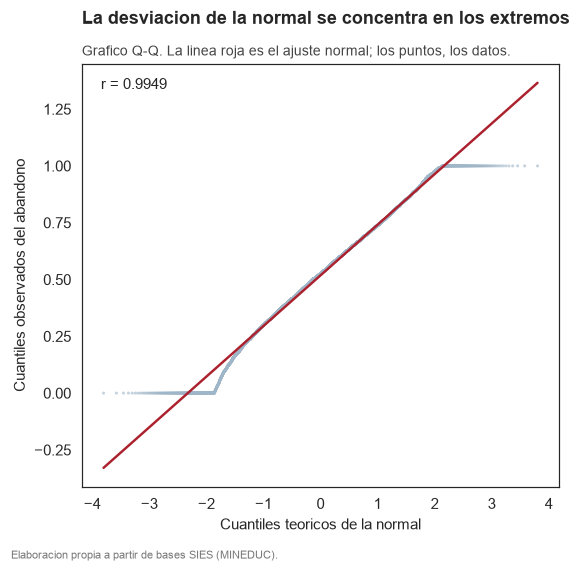

Correlacion cuantil-cuantil: r = 0.9949
Los puntos siguen la recta en el tramo central y se separan solo en las
colas, donde estan los programas acotados en 0 y en 1 del apartado 3.1.


In [26]:
# --- Figura: comprobacion grafica de la normalidad ------------------------
fig, eje = plt.subplots(figsize=(5.6, 5.0))
(osm, osr), (pendiente, origen, r) = stats.probplot(abandono, dist="norm", plot=None, fit=True)
eje.scatter(osm, osr, s=4, color=NEUTRO, edgecolors="none", alpha=0.6)
eje.plot(osm, pendiente * osm + origen, color=DESTACADO, linewidth=1.6)
eje.set_xlabel("Cuantiles teoricos de la normal")
eje.set_ylabel("Cuantiles observados del abandono")
eje.text(0.04, 0.94, f"r = {r:.4f}", transform=eje.transAxes, fontsize=9.5)
rotular(eje,
        "La desviacion de la normal se concentra en los extremos",
        "Grafico Q-Q. La linea roja es el ajuste normal; los puntos, los datos.")
guardar(fig, "fig7_qq")
plt.show()
print(f"Correlacion cuantil-cuantil: r = {r:.4f}")
print("Los puntos siguen la recta en el tramo central y se separan solo en las")
print("colas, donde estan los programas acotados en 0 y en 1 del apartado 3.1.")

### 5.3 Contraste 1 — El abandono frente a la mitad de la cohorte *(t de una muestra)*

La primera pregunta no compara grupos: contrasta el sistema con un valor de
referencia. Que la mitad de una cohorte no se titule es el umbral que la
discusión pública suele tomar como señal de alarma, de modo que cabe preguntar
si el abandono medio del sistema difiere de él.

> **H₀:** μ = 0,50   ·   **H₁:** μ ≠ 0,50   ·   α = 0,05

In [27]:
REFERENCIA = 0.50
t_una, p_una = stats.ttest_1samp(abandono, REFERENCIA)
d_una = (abandono.mean() - REFERENCIA) / abandono.std()

print(f"Media observada:     {abandono.mean():.4f}")
print(f"Valor de referencia: {REFERENCIA:.2f}")
print(f"Diferencia:          {abandono.mean() - REFERENCIA:+.4f}")
print(f"Estadistico t:       {t_una:.3f}   gl = {len(abandono)-1:,}".replace(",", "."))
print(f"Valor p:             {p_una:.3e}")
print(f"Decision:            {'se rechaza H0' if p_una < ALFA else 'no se rechaza H0'} al 5 %")
print(f"IC 95 % de la media: [{media['inferior']:.4f}, {media['superior']:.4f}]")
print(f"d de Cohen:          {d_una:.3f}")

Media observada:     0.5183
Valor de referencia: 0.50
Diferencia:          +0.0183
Estadistico t:       8.036   gl = 9.677
Valor p:             1.035e-15
Decision:            se rechaza H0 al 5 %
IC 95 % de la media: [0.5138, 0.5227]
d de Cohen:          0.082


Se rechaza la hipótesis nula: el abandono medio supera el 50 % de la cohorte.
Pero la magnitud de esa superación es de **1,8 puntos porcentuales**, y la
**d de Cohen vale 0,082**, muy por debajo del umbral de 0,2 que la convención
considera un efecto pequeño.

El resultado es instructivo precisamente por eso. Con un valor p de 10⁻¹⁵
cualquier lectura apresurada concluiría que el sistema está claramente por
encima del umbral de alarma, cuando lo que los datos muestran es que está
**prácticamente sobre él**. El contraste detecta la diferencia porque el
tamaño muestral se lo permite, no porque la diferencia importe.

### 5.4 Contraste 2 — La proporción de programas sobre el umbral *(Z de una muestra)*

La segunda pregunta es la misma trasladada a una proporción: ¿superan el umbral
más de la mitad de los programas, o la distribución se reparte en partes
iguales? Al tratarse de una proporción con *n* grande, el contraste adecuado es
el de Z, cuyo error estándar se calcula bajo la hipótesis nula.

> **H₀:** p = 0,50   ·   **H₁:** p ≠ 0,50   ·   α = 0,05

In [28]:
P0 = 0.50
exitos_z = int((abandono > 0.5).sum())
n_z = len(abandono)
p_obs = exitos_z / n_z

ee_h0 = np.sqrt(P0 * (1 - P0) / n_z)        # error estandar bajo la hipotesis nula
z_obs = (p_obs - P0) / ee_h0
p_z = 2 * (1 - stats.norm.cdf(abs(z_obs)))
# Tamanio del efecto para proporciones: h de Cohen, sobre la escala angular.
h_cohen = 2 * np.arcsin(np.sqrt(p_obs)) - 2 * np.arcsin(np.sqrt(P0))

print(f"Proporcion observada: {p_obs:.4f}   ({exitos_z:,} de {n_z:,})".replace(",", "."))
print(f"Valor de referencia:  {P0:.2f}")
print(f"Error estandar bajo H0: {ee_h0:.5f}")
print(f"Estadistico Z:        {z_obs:.3f}")
print(f"Valor p:              {p_z:.3e}")
print(f"Decision:             {'se rechaza H0' if p_z < ALFA else 'no se rechaza H0'} al 5 %")
print(f"IC 95 % de Wilson:    [{wilson[0]:.4f}, {wilson[1]:.4f}]")
print(f"h de Cohen:           {h_cohen:.3f}")

Proporcion observada: 0.5494   (5.317 de 9.678)
Valor de referencia:  0.50
Error estandar bajo H0: 0.00508
Estadistico Z:        9.718
Valor p:              0.000e+00
Decision:             se rechaza H0 al 5 %
IC 95 % de Wilson:    [0.5395, 0.5593]
h de Cohen:           0.099


También se rechaza: los programas que superan el umbral son más de la mitad.
Y de nuevo el tamaño del efecto lo relativiza, con una **h de Cohen de 0,099**
que no alcanza el rango de los efectos pequeños.

Los dos contrastes de una muestra coinciden, por tanto, en una misma lectura:
**el sistema chileno se sitúa justo en el umbral del 50 %, no claramente por
encima**. Esa conclusión no se obtiene del valor p, que en ambos casos invita a
afirmar lo contrario, sino de la magnitud del efecto.

### 5.5 Contraste 3 — Acreditación institucional *(t de Welch)*

> **H₀:** μ(nunca acreditada) = μ(siempre acreditada)
> **H₁:** μ(nunca acreditada) ≠ μ(siempre acreditada)   ·   α = 0,05

In [29]:
t_obs, p_valor = stats.ttest_ind(nunca, siempre, equal_var=False)

# Tamanio del efecto: d de Cohen con desviacion combinada.
n1, n2 = len(nunca), len(siempre)
v1, v2 = nunca.var(ddof=1), siempre.var(ddof=1)
s_combinada = np.sqrt(((n1 - 1) * v1 + (n2 - 1) * v2) / (n1 + n2 - 2))
d_cohen = (nunca.mean() - siempre.mean()) / s_combinada

print(f"Estadistico t de Welch: {t_obs:.3f}")
print(f"Grados de libertad:     {dif['gl']:.0f}")
print(f"Valor p:                {p_valor:.3e}")
print(f"Decision:               {'se rechaza H0' if p_valor < ALFA else 'no se rechaza H0'} al 5 %")
print()
print(f"Diferencia de medias:   {dif['diferencia']:+.4f}  IC 95 % [{dif['inferior']:.4f}, {dif['superior']:.4f}]")
print(f"d de Cohen:             {d_cohen:.3f}  (convencion: 0,2 pequenio | 0,5 medio | 0,8 grande)")

Estadistico t de Welch: 20.612
Grados de libertad:     902
Valor p:                1.167e-77
Decision:               se rechaza H0 al 5 %

Diferencia de medias:   +0.1757  IC 95 % [0.1590, 0.1924]
d de Cohen:             0.804  (convencion: 0,2 pequenio | 0,5 medio | 0,8 grande)


Se rechaza la hipótesis nula. Los programas de instituciones nunca acreditadas
presentan un abandono **17,6 puntos porcentuales mayor**, con un intervalo que
va de 15,9 a 19,2 puntos.

Lo decisivo aquí no es el valor p —con estos tamaños muestrales casi cualquier
diferencia resultaría significativa— sino la **d de Cohen de 0,80**, que la
convención sitúa en el umbral de los efectos grandes. Dicho de otro modo: la
acreditación no solo distingue grupos de forma detectable, sino de forma
sustantiva.

### 5.6 Contraste 4 — Área del conocimiento *(ANOVA de un factor)*

> **H₀:** μ₁ = μ₂ = … = μ₁₀ (las diez áreas comparten el mismo abandono esperado)
> **H₁:** al menos una difiere   ·   α = 0,05

In [30]:
grupos = [valores.values for _, valores in datos.groupby("area_del_conocimiento")["abandono"]]
f_obs, p_anova = stats.f_oneway(*grupos)

# Tamanio del efecto: eta cuadrado, la fraccion de varianza explicada.
media_global = abandono.mean()
sc_entre = sum(len(g) * (g.mean() - media_global) ** 2 for g in grupos)
sc_total = ((abandono - media_global) ** 2).sum()
eta2 = sc_entre / sc_total

k, N = len(grupos), len(abandono)
print(f"Estadistico F:      {f_obs:.3f}")
miles = lambda x: format(x, ",").replace(",", ".")
print(f"Grados de libertad: ({k-1}, {miles(N-k)})")
print(f"Valor p:            {p_anova:.3e}")
print(f"Decision:           {'se rechaza H0' if p_anova < ALFA else 'no se rechaza H0'} al 5 %")
print()
print(f"Eta cuadrado:       {eta2:.4f}  ->  el area explica el {eta2*100:.1f} % de la varianza")
print("Convencion: 0,01 pequenio | 0,06 medio | 0,14 grande")

Estadistico F:      44.298
Grados de libertad: (9, 9.668)
Valor p:            1.241e-78
Decision:           se rechaza H0 al 5 %

Eta cuadrado:       0.0396  ->  el area explica el 4.0 % de la varianza
Convencion: 0,01 pequenio | 0,06 medio | 0,14 grande


In [31]:
# Que pares difieren: comparaciones multiples de Tukey, que controlan el error
# por familia. Se muestran las diferencias mas grandes.
tukey = pairwise_tukeyhsd(datos["abandono"], datos["area_del_conocimiento"], alpha=ALFA)
comparaciones = pd.DataFrame(tukey.summary().data[1:], columns=tukey.summary().data[0])
comparaciones["meandiff"] = comparaciones["meandiff"].astype(float)
significativas = comparaciones[comparaciones["reject"]]
print(f"Pares comparados: {len(comparaciones)} | con diferencia significativa: {len(significativas)}")
print()
print(significativas.reindex(significativas["meandiff"].abs().sort_values(ascending=False).index)
      .head(8).to_string(index=False))

Pares comparados: 45 | con diferencia significativa: 30

           group1      group2  meandiff  p-adj   lower   upper  reject
      Humanidades       Salud   -0.1742    0.0 -0.2551 -0.0933    True
          Derecho       Salud   -0.1724    0.0 -0.2225 -0.1223    True
Ciencias Sociales Humanidades    0.1693    0.0  0.0868  0.2517    True
Ciencias Sociales     Derecho    0.1675    0.0  0.1149  0.2201    True
        Educación Humanidades    0.1663    0.0  0.0854  0.2472    True
          Derecho   Educación   -0.1645    0.0 -0.2146 -0.1144    True
     Agropecuaria Humanidades    0.1626    0.0  0.0704  0.2548    True
     Agropecuaria     Derecho    0.1608    0.0  0.0940  0.2277    True


Se rechaza la hipótesis nula: el abandono difiere entre áreas. Pero el tamaño
del efecto obliga a matizar la conclusión. **El área explica solo el 4 % de la
varianza** del abandono, un efecto que la convención califica de pequeño.

El contraste entre este resultado y el anterior es el hallazgo metodológico
central del trabajo. Ambos arrojan valores p ínfimos —10⁻⁷⁷ y 10⁻⁷⁸—, pero uno
corresponde a un efecto grande y el otro a uno pequeño. **Con 9.678
observaciones, el valor p pierde casi toda capacidad de discriminar**, porque
la potencia es tan alta que detecta diferencias triviales. Informar solo la
significación llevaría a tratar ambos resultados como equivalentes, que es
precisamente el error que la decisión de focalización no puede permitirse.

### 5.7 Contraste 5 — Tipo de institución y abandono alto *(chi-cuadrado)*

Para el tercer contraste ambas variables son cualitativas. El abandono se
dicotomiza en alto o bajo según la mediana del sistema, y se pregunta si esa
clasificación es independiente del tipo de institución.

> **H₀:** el tipo de institución y el nivel de abandono son independientes
> **H₁:** existe asociación entre ambos   ·   α = 0,05

In [32]:
datos["nivel_abandono"] = np.where(datos["abandono"] > abandono.median(), "Alto", "Bajo")
tabla = pd.crosstab(datos["clasificacion_institucion_nivel_3"], datos["nivel_abandono"])

chi2, p_chi, gl_chi, esperadas = stats.chi2_contingency(tabla)
v_cramer = np.sqrt(chi2 / (tabla.values.sum() * (min(tabla.shape) - 1)))

print("Tabla de contingencia observada")
print(tabla.to_string())
print()
print(f"Frecuencia esperada minima: {esperadas.min():.1f}  (el procedimiento exige al menos 5)")
print(f"Estadistico chi-cuadrado:   {chi2:.3f}")
print(f"Grados de libertad:         {gl_chi}")
print(f"Valor p:                    {p_chi:.3e}")
print(f"Decision:                   {'se rechaza H0' if p_chi < ALFA else 'no se rechaza H0'} al 5 %")
print()
print(f"V de Cramer:                {v_cramer:.3f}")
print("Convencion para gl = 5: 0,05 pequenio | 0,15 medio | 0,25 grande")

porcentajes = (tabla["Alto"] / tabla.sum(axis=1) * 100).sort_values(ascending=False)
print()
print("Porcentaje de programas con abandono alto, por tipo de institucion")
print(porcentajes.round(1).to_string())

Tabla de contingencia observada
nivel_abandono                          Alto  Bajo
clasificacion_institucion_nivel_3                 
Centros de Formación Técnica Estatales    15    12
Centros de Formación Técnica Privados   1220  1043
Institutos Profesionales                1989  1770
Universidades Estatales CRUCH            403   529
Universidades Privadas                   967  1045
Universidades Privadas CRUCH             245   440

Frecuencia esperada minima: 13.5  (el procedimiento exige al menos 5)
Estadistico chi-cuadrado:   102.505
Grados de libertad:         5
Valor p:                    1.566e-20
Decision:                   se rechaza H0 al 5 %

V de Cramer:                0.103
Convencion para gl = 5: 0,05 pequenio | 0,15 medio | 0,25 grande

Porcentaje de programas con abandono alto, por tipo de institucion
clasificacion_institucion_nivel_3
Centros de Formación Técnica Estatales    55.6
Centros de Formación Técnica Privados     53.9
Institutos Profesionales                

Se rechaza la independencia, pero la **V de Cramér de 0,103** sitúa la
asociación en el rango débil. Es la misma lección del contraste anterior: el
tipo de institución está asociado al abandono de forma estadísticamente
indudable y prácticamente modesta.

La figura 2 ya lo anticipaba al mostrar cajas muy solapadas. El contraste
confirma lo que el gráfico sugería: **conocer el tipo de institución de un
programa dice poco sobre su abandono**.

In [33]:
# Resumen de los tres contrastes, con su tamanio del efecto
contrastes = pd.DataFrame([
    {"Contraste": "t de una muestra", "Hipotesis nula": "El abandono medio es 0,50",
     "Estadistico": f"t = {t_una:.2f}", "gl": f"{len(abandono)-1}", "p": p_una,
     "Decision": "Se rechaza", "Tamanio del efecto": f"d = {d_una:.3f}", "Magnitud": "Despreciable"},
    {"Contraste": "Z de una muestra", "Hipotesis nula": "La proporcion sobre el umbral es 0,50",
     "Estadistico": f"Z = {z_obs:.2f}", "gl": "-", "p": p_z,
     "Decision": "Se rechaza", "Tamanio del efecto": f"h = {h_cohen:.3f}", "Magnitud": "Despreciable"},
    {"Contraste": "t de Welch", "Hipotesis nula": "Igual abandono segun acreditacion",
     "Estadistico": f"t = {t_obs:.2f}", "gl": f"{dif['gl']:.0f}", "p": p_valor,
     "Decision": "Se rechaza", "Tamanio del efecto": f"d = {d_cohen:.2f}", "Magnitud": "Grande"},
    {"Contraste": "ANOVA", "Hipotesis nula": "Igual abandono entre las 10 areas",
     "Estadistico": f"F = {f_obs:.2f}", "gl": f"{k-1}, {N-k}", "p": p_anova,
     "Decision": "Se rechaza", "Tamanio del efecto": f"eta2 = {eta2:.3f}", "Magnitud": "Pequenio"},
    {"Contraste": "Chi-cuadrado", "Hipotesis nula": "Independencia tipo de institucion / abandono",
     "Estadistico": f"chi2 = {chi2:.1f}", "gl": str(gl_chi), "p": p_chi,
     "Decision": "Se rechaza", "Tamanio del efecto": f"V = {v_cramer:.3f}", "Magnitud": "Debil"},
])
contrastes.to_csv(TABLAS / "contrastes_hipotesis.csv", index=False, encoding="utf-8-sig")
contrastes

,Contraste,Hipotesis nula,Estadistico,gl,p,Decision,Tamanio del efecto,Magnitud
0,t de una muestra,"El abandono medio es 0,50",t = 8.04,9677,1.035057e-15,Se rechaza,d = 0.082,Despreciable
1,Z de una muestra,"La proporcion sobre el umbral es 0,50",Z = 9.72,-,0.000000e+00,Se rechaza,h = 0.099,Despreciable
2,t de Welch,Igual abandono segun acreditacion,t = 20.61,902,1.167427e-77,Se rechaza,d = 0.80,Grande
3,ANOVA,Igual abandono entre las 10 areas,F = 44.30,"9, 9668",1.240963e-78,Se rechaza,eta2 = 0.040,Pequenio
4,Chi-cuadrado,Independencia tipo de institucion / abandono,chi2 = 102.5,5,1.566058e-20,Se rechaza,V = 0.103,Debil


## 6. Interpretación preliminar

**Los tres contrastes rechazan la hipótesis nula y, sin embargo, solo uno
orienta la decisión.** Esa es la conclusión que sostiene todo lo anterior.

Para la autoridad que debe repartir un presupuesto limitado de retención, los
resultados se traducen así:

**La magnitud justifica actuar.** El abandono esperado del sistema se estima en
0,518, con un intervalo de 0,514 a 0,523, y el 54,9 % de los programas supera
el 50 %. No se trata de un problema de casos aislados.

**La heterogeneidad justifica focalizar.** Con un coeficiente de variación de
0,43 y una mitad central que va de 0,376 a 0,669, los programas difieren
demasiado como para tratarlos igual. Si el abandono fuese uniforme, cualquier
reparto del presupuesto daría el mismo resultado.

**El criterio de focalización importa, y no todos valen.** La acreditación
institucional separa grupos con una diferencia de 17,6 puntos porcentuales y un
efecto grande (d = 0,80): es un criterio útil. El área del conocimiento y el
tipo de institución, en cambio, producen contrastes igual de significativos
pero con efectos pequeños —4 % de varianza explicada y V de Cramér de 0,103—:
usarlos como criterio principal repartiría recursos con poca ganancia, porque
la mayor parte de la variación ocurre *dentro* de cada categoría y no entre
ellas.

**La incertidumbre acompaña, pero no impide decidir.** Los intervalos son
estrechos y la diferencia por acreditación es compatible con los datos en todo
su rango, desde 15,9 hasta 19,2 puntos porcentuales. Ninguna de las
conclusiones anteriores depende del extremo del intervalo que se tome.

La recomendación preliminar, por tanto, no es focalizar por categorías
administrativas sino por el **nivel de abandono medido en cada programa**,
usando la acreditación como señal complementaria. Las categorías agregadas son
demasiado gruesas para capturar dónde está realmente el problema.

## 7. Limitaciones

**El abandono es aparente, no observado.** Con datos agregados, quien se cambia
de carrera y se titula en otra parte cuenta como abandono. La magnitud
estimada es una cota superior.

**La unidad de análisis es el programa.** Las conclusiones no pueden
trasladarse a individuos sin incurrir en falacia ecológica: que los programas
de instituciones no acreditadas tengan más abandono no permite afirmar nada
sobre la probabilidad de que un estudiante concreto abandone.

**Las asociaciones no son causas.** No hay grupo de control ni asignación
aleatoria. La acreditación podría estar recogiendo el efecto de la selectividad
del ingreso, de los recursos de la institución o del perfil socioeconómico de
sus estudiantes. El análisis identifica factores asociados y deja abierta su
explicación.

**La ventana temporal trunca las cohortes recientes.** Los programas cuya
cohorte teórica de egreso cae cerca de 2025 solo alcanzan a mostrar a quienes
se titularon a tiempo, lo que infla su abandono aparente.

**Los contrastes son univariados.** Cada uno examina un factor por separado, de
modo que los efectos podrían estar confundidos entre sí: las áreas con más
abandono podrían serlo por concentrarse en instituciones no acreditadas. Un
modelo multivariado, previsto para la fase siguiente, permitiría estimar cada
efecto manteniendo los demás constantes.

## 8. Próximos pasos

El análisis realizado es univariado: cada factor se examina por separado. Esa
es su principal limitación y define la agenda de la fase siguiente.

**1. Modelo multivariado.** Una regresión del abandono sobre el conjunto de
predictoras permitiría estimar el efecto de cada una manteniendo las demás
constantes. Es necesario porque el apartado 3.5 mostró colinealidad entre las
predictoras: los programas que reciben egresados de enseñanza
técnico-profesional son también los más cortos, de modo que hoy no puede
separarse qué parte del abandono corresponde a cada rasgo.

**2. Agrupación por institución.** Los programas de una misma institución
comparten políticas, infraestructura y selectividad, de modo que sus
observaciones no son independientes. Los errores estándar de este informe no
lo recogen, y un modelo con errores agrupados o una especificación jerárquica
corregiría esa subestimación.

**3. Ponderación por tamaño.** Aquí cada programa pesa igual, sea de 100 o de
9.994 estudiantes. Una estimación ponderada por el ingreso respondería una
pregunta distinta y complementaria: cuántos estudiantes, y no cuántos
programas, están expuestos a un abandono alto.

**4. Corregir el sesgo de truncamiento.** Restringir la lectura longitudinal a
las cohortes con ventana de exposición completa, y contrastar el abandono
aparente contra las bases de retención que publica el propio SIES, permitiría
acotar cuánto del abandono medido es cambio de carrera y cuánto es salida
efectiva del sistema.

**5. Capacidad predictiva.** Con el modelo ajustado podría evaluarse si el
abandono de un programa es anticipable a partir de sus características
observables, que es la pregunta que convierte el diagnóstico en un instrumento
de focalización.

In [34]:
# Trazabilidad: inventario de todo lo que este cuaderno deja escrito en disco.
salidas = sorted(list(FIGURAS.glob("*.png")) + list(TABLAS.glob("*.csv")))
inventario = pd.DataFrame([
    {"archivo": p.relative_to(RAIZ).as_posix(), "KB": round(p.stat().st_size / 1024, 1)}
    for p in salidas
])
print(inventario.to_string(index=False))
print(f"\n{len(inventario)} archivos generados; {len(datos):,} programas analizados.".replace(",", "."))

                                                                archivo    KB
                               resultados/figuras/fig1_distribucion.png  56.5
                           resultados/figuras/fig2_tipo_institucion.png  74.7
                                      resultados/figuras/fig3_areas.png 101.5
                                    resultados/figuras/fig4_tamanio.png 421.5
                                resultados/figuras/fig5_frecuencias.png 116.5
                              resultados/figuras/fig6_correlaciones.png 142.4
                                         resultados/figuras/fig7_qq.png  79.3
                                    resultados/tablas/calidad_datos.csv   0.4
                             resultados/tablas/contrastes_hipotesis.csv   0.6
                             resultados/tablas/descriptiva_abandono.csv   0.4
                            resultados/tablas/descriptiva_numericas.csv   1.5
            resultados/tablas/descriptiva_por_area_del_conocimie